## 1. Setup: import tools and choose settings

In [1]:
# ---- Import the libraries we need (the cell installs any that are missing) ----
import os, sys, ast, warnings, importlib, subprocess
warnings.filterwarnings("ignore")                      # keep the output clean
for package in ["catboost", "lightgbm", "optuna", "shap", "openpyxl"]:
    try:
        importlib.import_module(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np                                     # numbers and arrays
import pandas as pd                                    # tables
import matplotlib.pyplot as plt                        # plots
import seaborn as sns
import shap                                            # explains model predictions
import optuna                                          # Bayesian optimisation (used in the article)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer               # fills in missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.svm import SVR, LinearSVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

In [2]:
# ---- Where is the data? (Colab mounts Google Drive; otherwise we look in the current folder) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH  = "/content/drive/MyDrive/resume projects/BTP/sodium_ion_database.xlsx"
    OUTPUT_DIR = "/content/drive/MyDrive/resume projects/BTP/"
except ImportError:
    DATA_PATH  = os.environ.get("SODIUM_DB", "sodium_ion_database.xlsx")
    OUTPUT_DIR = os.environ.get("MODEL_OUT", ".")

# ---- Settings you can change ----
RANDOM_SEED   = 42      # makes results repeatable
N_REPEATS     = 3       # how many times each model test is repeated with different random splits
N_TRIALS      = 1000    # how many compositions the optimiser tries
C_RATE_TO_MAG = 150     # we assume 1C = 150 mA/g when a paper gives the current only as a C-rate
MAX_CAPACITY  = 300     # first-cycle capacities above this (mAh/g) are treated as unit errors

# ---- Conditions we want the new composition optimised FOR (same idea as the article) ----
DESIGN = dict(cycle=20, current=15.0, v_low=2.0, v_high=4.2, sinter_temp=800.0, sinter_time=12.0, phase="O3")
NA_CONTENT = 1.0        # O3-type NaMeO2 has one Na per formula unit

# ---- We have no voltage data, so we ASSUME an average voltage for each redox metal (volts) ----
ASSUMED_VOLTAGE = {"Ni": 3.3, "Mn": 2.7, "Fe": 3.3}
print("Settings ready. Data file:", DATA_PATH)

Mounted at /content/drive
Settings ready. Data file: /content/drive/MyDrive/resume projects/BTP/sodium_ion_database.xlsx


## 2. Load the raw database
Each row is one measurement from one paper: a material, a test condition and a result (capacity or retention).

In [3]:
# ---- Read the Excel file and give the columns short, easy names ----
raw = pd.read_excel(DATA_PATH)
raw = raw.rename(columns={
    "Sintering temperature": "Tsint",  "Sintering time": "tsint",   "Category": "Category",
    "Capacity": "Capacity",            "Retention": "Retention",
    "Current: mAg-1": "I_mAg",         "Current: C": "I_C",
    "Voltage lower limit": "Vlo",      "Voltage upper limit": "Vhi"})
print("Rows:", len(raw), "| papers:", raw["Doi"].nunique(), "| different materials:", raw["Name"].nunique())
print(raw["Category"].value_counts().to_string())

Rows: 5265 | papers: 514 | different materials: 693
Category
Cycling performance    3557
Rate performance       1708


In [4]:
raw.head()

,Doi,Year,Name,Abbreviation,Tsint,tsint,Category,Cycle,Capacity,Retention,I_mAg,I_C,Vlo,Vhi,Elements
0,10.1016/j.actamat.2020.08.015,2020,NaNi0.67SbO2,NaN,800.0,15.0,Cycling performance,1.0,102.5,NaN,NaN,NaN,2.0,4.0,"{'Na': '1', 'Ni': '0.67', 'Sb': '1', 'O': '2'}"
1,10.1016/j.actamat.2020.08.015,2020,NaRu0.03Ni0.67Sb0.3O2,NaN,800.0,15.0,Cycling performance,1.0,103.9,NaN,NaN,NaN,2.0,4.0,"{'Na': '1', 'Ru': '0.03', 'Ni': '0.67', 'Sb': ..."
2,10.1016/j.actamat.2020.08.015,2020,NaRu0.07Ni0.67Sb0.27O2,NaN,800.0,15.0,Cycling performance,1.0,112.7,NaN,NaN,NaN,2.0,4.0,"{'Na': '1', 'Ru': '0.07', 'Ni': '0.67', 'Sb': ..."
3,10.1016/j.actamat.2020.08.015,2020,NaRu0.1Ni0.67Sb0.23O2,NaN,800.0,15.0,Cycling performance,1.0,117.8,NaN,NaN,NaN,2.0,4.0,"{'Na': '1', 'Ru': '0.1', 'Ni': '0.67', 'Sb': '..."
4,10.1016/j.actamat.2020.08.015,2020,NaRu0.07Ni0.67Sb0.27O2,NaN,800.0,15.0,Rate performance,NaN,114.6,NaN,20.0,NaN,2.0,4.0,"{'Na': '1', 'Ru': '0.07', 'Ni': '0.67', 'Sb': ..."


In [5]:
# ---- The 'Elements' column is text like "{'Na': '1', 'Mn': '0.5', 'Ni': '0.5', 'O': '2'}".
# ---- We turn it into one numeric column per element (frac_Na, frac_Mn, ...). ----
def parse_elements(text):
    result = {}
    for element, amount in ast.literal_eval(text).items():
        result[element] = float(amount)
    return result

element_table = pd.DataFrame([parse_elements(t) for t in raw["Elements"]]).fillna(0.0)
element_table.columns = ["frac_" + c for c in element_table.columns]
data = pd.concat([raw.drop(columns=["Elements"]), element_table], axis=1)
FRAC_COLS = list(element_table.columns)

# ---- One current column in mA/g (convert C-rates with our assumption) ----
data["I"] = data["I_mAg"].where(data["I_mAg"].notna(), data["I_C"] * C_RATE_TO_MAG)

# ---- Phase (P2 / O3 / P3) is written at the start of some names, e.g. 'P2-Na0.67...' ----
data["Phase"] = data["Name"].str.extract(r"^(P2|O3|P3|O2|P'2|O'3)-")[0].fillna("Unspecified")

print("Number of element columns:", len(FRAC_COLS))
print("Phase labels found in the names:")
print(data["Phase"].value_counts().to_string())
share_labelled = 100 * (data["Phase"] != "Unspecified").mean()
print(f"\nINSIGHT: only {share_labelled:.0f}% of rows have a phase label in the name, so phase information is limited.")

Number of element columns: 36
Phase labels found in the names:
Phase
Unspecified    3644
P2             1125
O3              425
P3               71

INSIGHT: only 31% of rows have a phase label in the name, so phase information is limited.


In [6]:
print(FRAC_COLS)

['frac_Na', 'frac_Ni', 'frac_Sb', 'frac_O', 'frac_Ru', 'frac_Mn', 'frac_Fe', 'frac_Cu', 'frac_Co', 'frac_Cr', 'frac_Li', 'frac_Ti', 'frac_Zn', 'frac_F', 'frac_Sr', 'frac_Mg', 'frac_Nb', 'frac_Mo', 'frac_La', 'frac_K', 'frac_V', 'frac_B', 'frac_Sn', 'frac_Zr', 'frac_Bi', 'frac_Si', 'frac_Ca', 'frac_Al', 'frac_Y', 'frac_In', 'frac_Rb', 'frac_Te', 'frac_N', 'frac_Cl', 'frac_Ge', 'frac_Ir']


In [7]:
# ---- Remove rows tested in anode-type voltage windows (e.g. 0.01-2.5 V). We want CATHODE data. ----
anode_like = (data["Vlo"] < 1.0) | (data["Vhi"] < 3.0)
print("Rows removed because they look like anode tests:", int(anode_like.sum()))
data = data[~anode_like].copy()

Rows removed because they look like anode tests: 179


## 3. Build the two modelling tables
* **Initial capacity table:** the capacity measured in the *first* cycle.
* **Retention table:** retention = (capacity after N cycles) / (capacity in cycle 1) x 100. Some papers report retention directly; for others we compute it from their capacity values.

A **series** means one test curve: the same paper, material, current and voltage window.

In [8]:
# ---- Missing values in the series keys are replaced by -1 so that pandas can group on them ----
data["I_key"]   = data["I"].fillna(-1)
data["Vlo_key"] = data["Vlo"].fillna(-1)
data["Vhi_key"] = data["Vhi"].fillna(-1)
series_key = ["Doi", "Name", "I_key", "Vlo_key", "Vhi_key"]
cycling = data[data["Category"] == "Cycling performance"].copy()

# ---- (a) Initial capacity = capacity at cycle 1 (median if a curve has several values) ----
first_cycle = cycling[(cycling["Cycle"] == 1) & cycling["Capacity"].notna()]
cap1 = first_cycle.groupby(series_key).agg(y=("Capacity", "median"), n_values=("Capacity", "size")).reset_index()

# ---- (b1) Retention that papers REPORTED directly ----
reported = cycling[cycling["Retention"].notna()].copy()
reported["y"] = reported["Retention"]

# ---- (b2) Retention we CALCULATE: capacity(cycle N) / capacity(cycle 1) x 100, same series ----
later = cycling[(cycling["Cycle"] > 1) & cycling["Capacity"].notna()]
later = later.merge(cap1[cap1["n_values"] == 1][series_key + ["y"]].rename(columns={"y": "Cap_first"}), on=series_key)
later["y"] = 100 * later["Capacity"] / later["Cap_first"]

# ---- Put reported and calculated retention together, remove duplicates and impossible values ----
keep_cols = [c for c in data.columns if c not in ("I_key", "Vlo_key", "Vhi_key")] + ["y"]
ret = pd.concat([reported[keep_cols], later[keep_cols]], ignore_index=True)
ret = ret[(ret["y"] > 0) & (ret["y"] <= 130)]
ret["y_rounded"] = ret["y"].round(1)
ret = ret.drop_duplicates(["Doi", "Name", "Cycle", "I", "Vlo", "Vhi", "y_rounded"]).drop(columns="y_rounded")
ret = ret[ret["Vlo"].notna()].reset_index(drop=True)            # the article always knows the voltage window

# ---- Add the material information (composition, phase, sintering) to the capacity table ----
material_info = data.drop_duplicates(["Doi", "Name"])[["Doi", "Name", "Phase", "Tsint", "tsint"] + FRAC_COLS]
cap = cap1.merge(material_info, on=["Doi", "Name"], how="left")
cap["I"]   = cap["I_key"].where(cap["I_key"] > 0)               # -1 means unknown -> back to missing
cap["Vlo"] = cap["Vlo_key"].where(cap["Vlo_key"] >= 0)
cap["Vhi"] = cap["Vhi_key"].where(cap["Vhi_key"] >= 0)
cap = cap[(cap["y"] <= MAX_CAPACITY) & cap["Vlo"].notna()].reset_index(drop=True)
ret["logC"] = np.log1p(ret["Cycle"])                            # log of the cycle number (fade is not linear)

print(f"Initial-capacity table : {len(cap)} rows from {cap['Doi'].nunique()} papers")
print(f"Retention table        : {len(ret)} rows from {ret['Doi'].nunique()} papers")

Initial-capacity table : 834 rows from 323 papers
Retention table        : 1067 rows from 323 papers


###in this we can also calculate retention for more than one records containing 1 cycle as the medium capacity


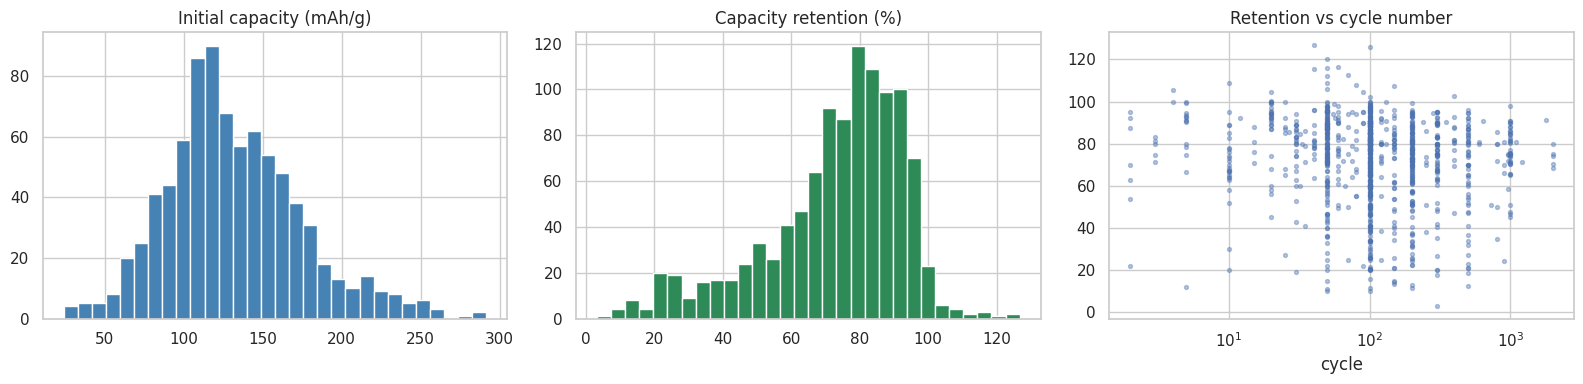

INSIGHT: capacity averages 132 mAh/g with a spread (std) of 43.
INSIGHT: retention ranges from 3% to 127% (std 20). the wide range is due to different experimental conditions and wide spread of literature data.


In [9]:
# ---- Look at the targets we want to predict ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(cap["y"], bins=30, color="steelblue");  axes[0].set_title("Initial capacity (mAh/g)")
axes[1].hist(ret["y"], bins=30, color="seagreen");   axes[1].set_title("Capacity retention (%)")
axes[2].scatter(ret["Cycle"], ret["y"], s=8, alpha=0.4); axes[2].set_xscale("log")
axes[2].set_title("Retention vs cycle number"); axes[2].set_xlabel("cycle")
plt.tight_layout(); plt.show()

print(f"INSIGHT: capacity averages {cap['y'].mean():.0f} mAh/g with a spread (std) of {cap['y'].std():.0f}.")
print(f"INSIGHT: retention ranges from {ret['y'].min():.0f}% to {ret['y'].max():.0f}% (std {ret['y'].std():.0f}). "
      "the wide range is due to different experimental conditions and wide spread of literature data.")

## 4. Turn each material into numbers the model can use (features)
The article used the **metal fractions** and the **voltage window**. We add a few easy chemistry features that help the model:
* the *average oxidation state* of the redox metals (from charge balance),
* the *share* of Mn, Ni, Co, Fe, Cu, Ti on the metal site,
* a *textbook capacity* from the number of electrons the metals can give,
* the test **current**, the **phase** and the **sintering** conditions (these differ a lot between papers).

In [10]:
# ---- Small chemistry look-up tables ----
'''
redox_metals: Lists elements that can actively change their oxidation states (gain/lose electrons) to store and release charge in a battery.
inactive_metals: Lists elements that remain stable and do not participate in redox reactions, usually acting as structural stabilizers.
fixed_charge: Defines the assumed constant electrical charge (valence state) for non-redox active ions when dissolved in the crystal lattice.
electronegativity: Stores Pauling electronegativity values, which measure how strongly each atom attracts electrons.
atomic_mass: Contains atomic masses used to calculate the overall formula mass of any custom material recipe.
highest_oxidation: Establishes the maximum realistic oxidation state each redox-active metal can achieve during fully charged battery states.
get_fraction() Helper: A safety function that retrieves an element's percentage in a formula, returning 0.0 if that element is not part of the chemical recipe.
'''
redox_metals    = ["Mn", "Ni", "Co", "Fe", "Cu", "Cr", "V", "Ru", "Ir"]            # metals that give/take electrons
inactive_metals = ["Li", "Mg", "Zn", "Al", "Ti", "Zr", "Sn", "Sb", "Nb", "Te", "Mo", "In", "La", "Bi", "B", "Si", "Y", "Ge"]
fixed_charge = {"Li": 1, "K": 1, "Rb": 1, "Ca": 2, "Sr": 2, "Mg": 2, "Zn": 2, "Al": 3, "B": 3, "In": 3, "La": 3, "Bi": 3, "Y": 3,
                "Ti": 4, "Zr": 4, "Sn": 4, "Si": 4, "Ge": 4, "Sb": 5, "Nb": 5, "Te": 6, "Mo": 6}   # charge of non-redox ions
electronegativity = {"Al": 1.61, "B": 2.04, "Bi": 2.02, "Co": 1.88, "Cr": 1.66, "Cu": 1.90, "Fe": 1.83, "In": 1.78, "Ir": 2.20, "La": 1.10,
                     "Li": 0.98, "Mg": 1.31, "Mn": 1.55, "Mo": 2.16, "Nb": 1.60, "Ni": 1.91, "Ru": 2.20, "Sb": 2.05, "Si": 1.90, "Sn": 1.96,
                     "Te": 2.10, "Ti": 1.54, "V": 1.63, "Zn": 1.65, "Zr": 1.33, "Y": 1.22, "Ge": 2.01}
atomic_mass = {"Na": 22.99, "O": 16.0, "Li": 6.94, "Mg": 24.31, "Al": 26.98, "Ti": 47.87, "Cr": 52.0, "Mn": 54.94, "Fe": 55.85, "Co": 58.93,
               "Ni": 58.69, "Cu": 63.55, "Zn": 65.38, "Sn": 118.71, "Sb": 121.76, "Zr": 91.22, "V": 50.94, "Ru": 101.07, "Nb": 92.91,
               "Mo": 95.95, "Y": 88.91, "Ge": 72.63, "K": 39.1, "Ca": 40.08, "B": 10.81, "La": 138.9, "Te": 127.6, "Si": 28.09,
               "Bi": 209.0, "In": 114.8, "Rb": 85.47, "Sr": 87.62, "F": 19.0}
highest_oxidation = {"Mn": 4, "Ni": 4, "Co": 4, "Fe": 4, "Cu": 3, "Cr": 4, "V": 5, "Ru": 4}   # highest state we can realistically reach

def get_fraction(df, element):
    # returns the column frac_<element>, or zeros if that element never appears
    name = "frac_" + element
    if name in df.columns:
        return df[name]
    return pd.Series(0.0, index=df.index)

In [11]:
def make_features(df):
    # Adds our chemistry features to a table that has the frac_* columns, Vlo, Vhi, I, Tsint, tsint.
    df = df.copy()
    redox_total    = sum(get_fraction(df, e) for e in redox_metals)
    inactive_total = sum(get_fraction(df, e) for e in inactive_metals)
    metal_total    = redox_total + inactive_total

    # Charge balance: oxygen gives -2 (fluorine -1); Na and the inactive ions give +; the redox metals must make up the rest.
    charge_needed = 2 * get_fraction(df, "O") + get_fraction(df, "F") - get_fraction(df, "Na")
    for element, charge in fixed_charge.items():
        charge_needed = charge_needed - charge * get_fraction(df, element)
    df["avg_ox"] = (charge_needed / redox_total.where(redox_total > 0.05)).clip(0, 7)     # average oxidation state

    df["redox_total"] = redox_total
    df["inactive_share"] = inactive_total / metal_total.where(metal_total > 0)
    for e in ["Mn", "Ni", "Co", "Fe", "Cu", "Ti"]:
        df[e + "_share"] = get_fraction(df, e) / metal_total.where(metal_total > 0)

    en_sum = sum(electronegativity[e] * get_fraction(df, e) for e in redox_metals + inactive_metals)
    df["EN_metal"] = en_sum / metal_total.where(metal_total > 0)

    # Textbook capacity: electrons the redox metals can still give (up to Na), converted to mAh/g (26801 = Faraday / 3.6)
    electrons = sum(get_fraction(df, e) * np.clip(highest_oxidation[e] - df["avg_ox"], 0, None) for e in highest_oxidation)
    formula_mass = sum(get_fraction(df, e) * m for e, m in atomic_mass.items())
    df["textbook_cap"] = np.minimum(electrons, get_fraction(df, "Na")) * 26801 / formula_mass

    metal_cols = [c for c in ["frac_" + e for e in redox_metals + inactive_metals] if c in df.columns]
    df["n_metals"] = (df[metal_cols] > 0).sum(axis=1)
    df["dV"] = df["Vhi"] - df["Vlo"]                              # width of the voltage window
    df["logI"] = np.log10(df["I"])                                # log of the current
    df["I_missing"] = df["I"].isna().astype(int)                  # 1 if the paper did not state the current
    df["T_missing"] = df["Tsint"].isna().astype(int)
    return df

cap = make_features(cap)
ret = make_features(ret)

# ---- Which columns does the model get to see? ----
composition_cols = [c for c in FRAC_COLS if c != "frac_O"]
chem_cols        = ["avg_ox", "redox_total", "inactive_share", "Mn_share", "Ni_share", "Co_share", "Fe_share",
                    "Cu_share", "Ti_share", "EN_metal", "textbook_cap", "n_metals"]
condition_cols   = ["Vlo", "Vhi", "dV", "logI", "I_missing"]
process_cols     = ["Tsint", "tsint", "T_missing"]
category_cols    = ["Phase"]

features_capacity  = composition_cols + chem_cols + condition_cols + process_cols + category_cols
features_retention = features_capacity + ["logC"]                    # retention also depends on the cycle number
article_inputs_cap = composition_cols + ["Vlo", "Vhi", "logI"]        # what the article used (+ current)
article_inputs_ret = article_inputs_cap + ["logC"]
print("Features for capacity :", len(features_capacity))
print("Features for retention:", len(features_retention))

Features for capacity : 56
Features for retention: 57


## 5. Test the article's 8 models on our data
We use the same 8 algorithms as the article. Each is tested three ways:

| Test | What it means | How hard |
|---|---|---|
| **Random 80/20** | hide a random 20% of rows (the article's test) | easiest, rows from the same paper can leak into both sets |
| **Unseen composition** | hide whole materials | harder |
| **Unseen paper** | hide whole papers, like predicting a brand-new study | hardest, and the honest one |

**R² = 1** is perfect, **R² = 0** is no better than always guessing the average. **RMSE** is the typical error (smaller is better).

In [12]:
# ---- The 8 models of the article ----
models = {
    "Lasso":         Lasso(alpha=0.05),
    "Ridge":         Ridge(alpha=10),
    "Linear SVR":    LinearSVR(C=1.0, max_iter=20000),
    "Kernel SVR":    SVR(kernel="rbf", C=10),
    "ElasticNet":    ElasticNet(alpha=0.05, l1_ratio=0.5),
    "PLS":           PLSRegression(n_components=5),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
    "LightGBM":      LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=5, verbose=-1, random_state=RANDOM_SEED),
}

def make_pipeline(model, feature_list):
    # Pipeline = (1) fill missing numbers with the median, (2) scale them, (3) one-hot encode text columns, (4) the model.
    numeric = [c for c in feature_list if c not in category_cols]
    text    = [c for c in feature_list if c in category_cols]
    parts = [("numbers", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric)]
    if text:
        parts.append(("text", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), text))
    return Pipeline([("prepare", ColumnTransformer(parts)), ("model", model)])

In [13]:
def run_benchmark(table, feature_list, title):
    # Tests every model with the three splitting methods, repeated N_REPEATS times.
    table = table.reset_index(drop=True)
    y = table["y"].values
    results = []
    for model_name, model in models.items():
        row = {"Model": model_name}
        for test_name in ["Random 80/20", "Unseen composition", "Unseen paper"]:
            r2_list, rmse_list = [], []
            for repeat in range(N_REPEATS):
                # choose which rows are used for training and which for testing
                if test_name == "Random 80/20":
                    train_idx, test_idx = train_test_split(np.arange(len(table)), test_size=0.2, random_state=repeat)
                else:
                    group_column = table["Name"] if test_name == "Unseen composition" else table["Doi"]
                    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=repeat)
                    train_idx, test_idx = next(splitter.split(table, y, group_column))
                pipe = make_pipeline(model, feature_list)
                pipe.fit(table.iloc[train_idx][feature_list], y[train_idx])
                prediction = np.ravel(pipe.predict(table.iloc[test_idx][feature_list]))
                r2_list.append(r2_score(y[test_idx], prediction))
                rmse_list.append(np.sqrt(mean_squared_error(y[test_idx], prediction)))
            row[test_name + " R2"] = np.mean(r2_list)
            row[test_name + " RMSE"] = np.mean(rmse_list)
        results.append(row)
    results = pd.DataFrame(results)
    print("=====", title, "=====")
    print(f"rows: {len(table)} | papers: {table['Doi'].nunique()} | spread of the target (std): {y.std():.1f}")
    display(results.round(2))
    return results

bench_cap = run_benchmark(cap, article_inputs_cap, "INITIAL CAPACITY (mAh/g)")

===== INITIAL CAPACITY (mAh/g) =====
rows: 834 | papers: 323 | spread of the target (std): 43.4


,Model,Random 80/20 R2,Random 80/20 RMSE,Unseen composition R2,Unseen composition RMSE,Unseen paper R2,Unseen paper RMSE
0,Lasso,0.22,38.10,0.14,40.01,0.16,41.35
1,Ridge,0.22,38.08,0.14,40.01,0.16,41.34
2,Linear SVR,0.18,39.08,0.03,42.30,0.06,43.68
3,Kernel SVR,0.22,38.08,0.13,40.16,0.14,41.76
4,ElasticNet,0.22,38.02,0.14,39.93,0.16,41.34
5,PLS,0.22,38.04,0.14,40.00,0.16,41.40
6,Random Forest,0.32,35.51,0.14,39.77,0.07,43.57
7,LightGBM,0.27,36.82,0.04,41.90,0.01,44.85


In [14]:
bench_ret = run_benchmark(ret, article_inputs_ret, "RETENTION (%)")

===== RETENTION (%) =====
rows: 1067 | papers: 323 | spread of the target (std): 20.4


,Model,Random 80/20 R2,Random 80/20 RMSE,Unseen composition R2,Unseen composition RMSE,Unseen paper R2,Unseen paper RMSE
0,Lasso,0.07,19.24,-0.02,20.01,-0.27,22.96
1,Ridge,0.07,19.29,-0.02,20.07,-0.30,23.15
2,Linear SVR,-0.07,20.65,-0.00,19.89,-0.07,21.33
3,Kernel SVR,0.03,19.68,-0.03,20.16,-0.07,21.34
4,ElasticNet,0.08,19.22,-0.01,19.98,-0.28,23.00
5,PLS,0.06,19.37,-0.03,20.17,-0.30,23.20
6,Random Forest,0.09,19.09,-0.06,20.40,0.02,20.39
7,LightGBM,0.09,19.06,-0.14,21.10,0.01,20.43


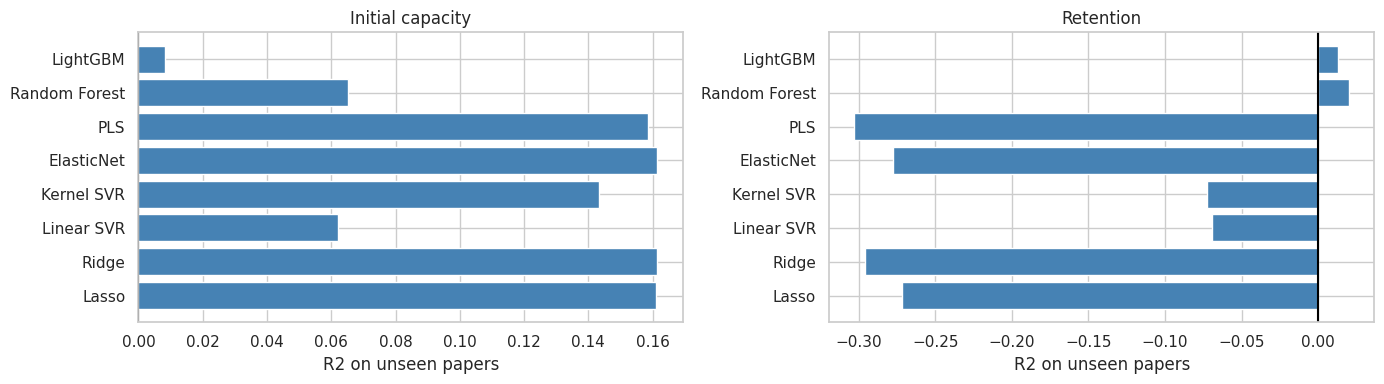

INSIGHT (capacity): the best model on unseen papers is Ridge with R2 = 0.16 and typical error 41 mAh/g. A small but real signal.
INSIGHT (retention): the best model on unseen papers has R2 = 0.02, so absolute retention is essentially NOT predictable from composition and voltage alone.
INSIGHT: the article reached errors of 15.8 mAh/g (capacity) and 4.6 % (retention) on its own single-lab data. Our literature data mixes many labs and test protocols, which is why our errors are larger.


In [15]:
# ---- Plot the honest test (unseen paper) for both targets, and print the story ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, table, name in [(axes[0], bench_cap, "Initial capacity"), (axes[1], bench_ret, "Retention")]:
    ax.barh(table["Model"], table["Unseen paper R2"], color="steelblue")
    ax.axvline(0, color="black"); ax.set_xlabel("R2 on unseen papers"); ax.set_title(name)
plt.tight_layout(); plt.show()

best_c = bench_cap.sort_values("Unseen paper R2", ascending=False).iloc[0]
best_r = bench_ret.sort_values("Unseen paper R2", ascending=False).iloc[0]
print(f"INSIGHT (capacity): the best model on unseen papers is {best_c['Model']} with R2 = {best_c['Unseen paper R2']:.2f} "
      f"and typical error {best_c['Unseen paper RMSE']:.0f} mAh/g. A small but real signal.")
print(f"INSIGHT (retention): the best model on unseen papers has R2 = {best_r['Unseen paper R2']:.2f}, "
      f"so absolute retention is essentially NOT predictable from composition and voltage alone.")
print("INSIGHT: the article reached errors of 15.8 mAh/g (capacity) and 4.6 % (retention) on its own single-lab data. "
      "Our literature data mixes many labs and test protocols, which is why our errors are larger.")

## 6. What did the models learn? (SHAP)
SHAP shows how much each input pushed a prediction up or down. We compare the direction with what the article found (its Fig. S4).
For retention we look at the *paper-adjusted* target (retention minus that paper's average), which removes differences between labs and keeps the effect of composition.

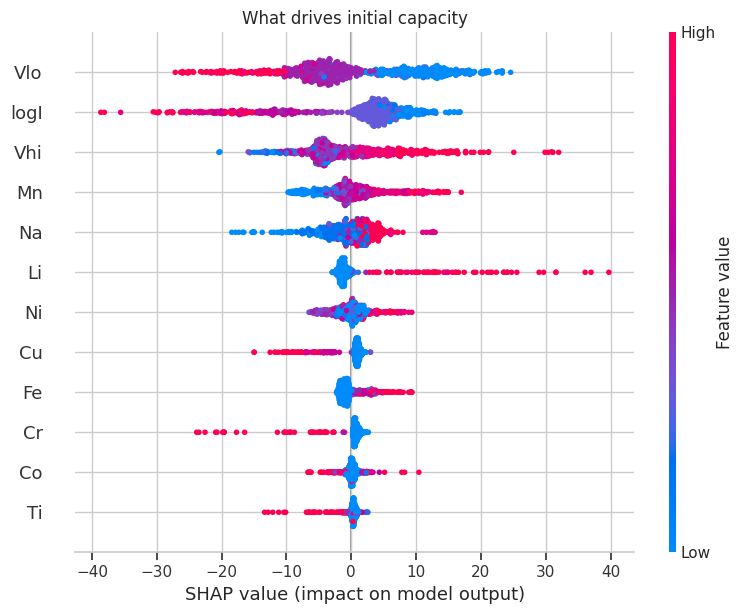

,Feature,Article says,Our data says,Agree?
0,Vhi,raises,raises,yes
1,Vlo,lowers,lowers,yes
2,Fe,lowers,raises,no
3,Sn,lowers,no clear effect,no
4,Al,lowers,no clear effect,no
5,Ti,lowers,lowers,yes
6,Mn,raises,raises,yes
7,Ni,raises,no clear effect,no


INSIGHT: our data agrees with the article on 4 of 8 points.


In [16]:
def shap_check(table, feature_list, target_values, article_claims, title):
    # Train a Random Forest, compute SHAP values, and compare the direction of each effect with the article.
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(table[feature_list]), columns=feature_list)
    forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.4, random_state=RANDOM_SEED, n_jobs=-1)
    forest.fit(X, target_values)
    shap_values = shap.TreeExplainer(forest).shap_values(X)
    well_used = [c for c in feature_list if (X[c] != 0).sum() >= 25]            # skip features that are almost always zero
    shap.summary_plot(shap_values[:, [feature_list.index(c) for c in well_used]], X[well_used],
                      feature_names=[c.replace("frac_", "") for c in well_used], show=False, max_display=12)
    plt.title(title); plt.tight_layout(); plt.show()

    rows = []
    for feature, article_says in article_claims.items():
        j = feature_list.index(feature)
        correlation = pd.Series(X[feature]).corr(pd.Series(shap_values[:, j]), method="spearman")
        ours = "raises" if correlation > 0.1 else ("lowers" if correlation < -0.1 else "no clear effect")
        rows.append({"Feature": feature.replace("frac_", ""), "Article says": article_says, "Our data says": ours,
                     "Agree?": "yes" if ours == article_says else "no"})
    result = pd.DataFrame(rows); display(result)
    print(f"INSIGHT: our data agrees with the article on {(result['Agree?'] == 'yes').sum()} of {len(result)} points.")

shap_check(cap, article_inputs_cap, cap["y"].values,
           {"Vhi": "raises", "Vlo": "lowers", "frac_Fe": "lowers", "frac_Sn": "lowers", "frac_Al": "lowers",
            "frac_Ti": "lowers", "frac_Mn": "raises", "frac_Ni": "raises"},
           "What drives initial capacity")

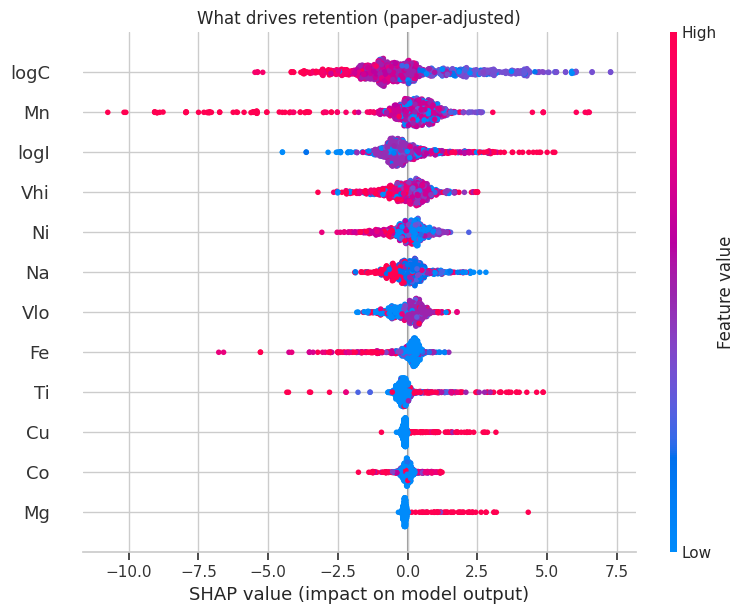

,Feature,Article says,Our data says,Agree?
0,Mn,raises,lowers,no
1,Ni,lowers,lowers,yes
2,Vhi,lowers,lowers,yes
3,Vlo,raises,raises,yes


INSIGHT: our data agrees with the article on 3 of 4 points.


In [17]:
retention_adjusted = ret["y"] - ret.groupby("Doi")["y"].transform("mean")        # retention minus the paper's average
shap_check(ret, article_inputs_ret, retention_adjusted.values,
           {"frac_Mn": "raises", "frac_Ni": "lowers", "Vhi": "lowers", "Vlo": "raises"},
           "What drives retention (paper-adjusted)")

## 7. The models used for the search
### 7a. Capacity model
Average of a Random Forest and a CatBoost model. Tested on **unseen papers** with 5-fold cross-validation (every fold hides whole papers).

Capacity model on unseen papers:  R2 = 0.20   typical error = 38.9 mAh/g   (spread of the data: 43.4)


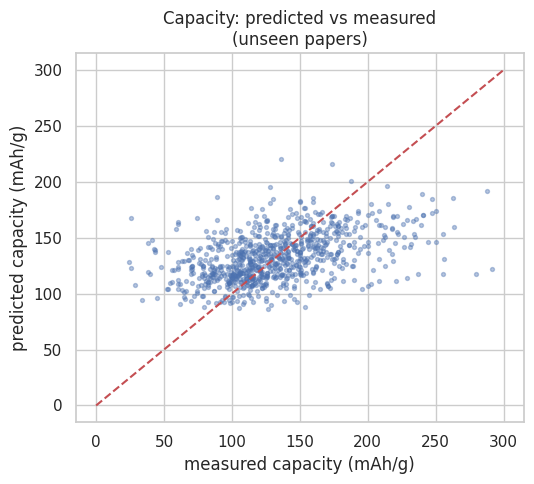

INSIGHT: the points follow the red line loosely. The model explains about 20% of the variation, enough to compare compositions, not enough to promise exact numbers.


In [18]:
cap_models = {
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=RANDOM_SEED),
    "CatBoost":     CatBoostRegressor(iterations=500, learning_rate=0.04, depth=5, l2_leaf_reg=5, verbose=0,
                                      random_seed=RANDOM_SEED, allow_writing_files=False),
}
y_cap = cap["y"].values
predicted_cap = np.zeros(len(cap))                                   # predictions for rows the model did not train on
for train_idx, test_idx in GroupKFold(n_splits=5).split(cap, y_cap, groups=cap["Doi"]):
    fold_predictions = []
    for model in cap_models.values():
        pipe = make_pipeline(model, features_capacity)
        pipe.fit(cap.iloc[train_idx][features_capacity], y_cap[train_idx])
        fold_predictions.append(pipe.predict(cap.iloc[test_idx][features_capacity]))
    predicted_cap[test_idx] = np.mean(fold_predictions, axis=0)

cap_r2 = r2_score(y_cap, predicted_cap)
cap_rmse = np.sqrt(mean_squared_error(y_cap, predicted_cap))
print(f"Capacity model on unseen papers:  R2 = {cap_r2:.2f}   typical error = {cap_rmse:.1f} mAh/g   (spread of the data: {y_cap.std():.1f})")

plt.figure(figsize=(5.5, 5)); plt.scatter(y_cap, predicted_cap, s=8, alpha=0.4)
plt.plot([0, 300], [0, 300], "r--"); plt.xlabel("measured capacity (mAh/g)"); plt.ylabel("predicted capacity (mAh/g)")
plt.title("Capacity: predicted vs measured\n(unseen papers)"); plt.tight_layout(); plt.show()
print(f"INSIGHT: the points follow the red line loosely. The model explains about {100*cap_r2:.0f}% of the variation, "
      "enough to compare compositions, not enough to promise exact numbers.")

### 7b. Retention model: ranking instead of exact numbers
Because absolute retention depends mostly on *which lab* tested the cell, we teach the model something easier and more useful:
**"given two compositions tested in the same paper under the same conditions, which one keeps its capacity better?"**
To do this the target is *retention minus that paper's average*. We then check how often the model puts two different compositions from an unseen paper in the right order (50% = coin flip).

In [19]:
retention_models = {
    "Ridge":        Ridge(alpha=30),
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=RANDOM_SEED),
    "CatBoost":     CatBoostRegressor(iterations=500, learning_rate=0.04, depth=5, l2_leaf_reg=5, verbose=0,
                                      random_seed=RANDOM_SEED, allow_writing_files=False),
}
y_ret = ret["y"].values
paper_ids = ret["Doi"].values

# ---- A "comparison group" = same paper, same cycle number, same current and same voltage window ----
group_label = (ret["Doi"] + "|" + ret["Cycle"].astype(str) + "|" + ret["I"].fillna(-1).astype(str) + "|"
               + ret["Vlo"].astype(str) + "|" + ret["Vhi"].astype(str)).values
composition_label = ret[FRAC_COLS].round(3).astype(str).agg("|".join, axis=1).values      # identical recipes get the same label

def ranking_accuracy(predictions):
    # Counts how often the model orders two DIFFERENT compositions of the same group correctly.
    table = pd.DataFrame({"group": group_label, "actual": y_ret, "predicted": predictions, "recipe": composition_label})
    correct, total, best_hits, best_chance = 0.0, 0, [], []
    pair_results = []
    for _, g in table.groupby("group"):
        if g["recipe"].nunique() < 2:
            continue
        g = g.groupby("recipe").agg(actual=("actual", "mean"), predicted=("predicted", "mean")).reset_index()   # average replicates
        if len(g) < 2 or g["actual"].nunique() < 2:
            continue
        best_hits.append(g["predicted"].values.argmax() == g["actual"].values.argmax())
        best_chance.append(1 / len(g))
        right, pairs = 0.0, 0
        for i in range(len(g)):
            for j in range(i + 1, len(g)):
                if g["actual"].values[i] != g["actual"].values[j]:
                    pairs += 1
                    same_order = (g["predicted"].values[i] - g["predicted"].values[j]) * (g["actual"].values[i] - g["actual"].values[j]) > 0
                    right += 1.0 if same_order else 0.0
        pair_results.append((right, pairs))
    pair_results = np.array(pair_results)
    return pair_results[:, 0].sum() / pair_results[:, 1].sum(), np.mean(best_hits), np.mean(best_chance), pair_results

# ---- Cross-validation: whole papers are hidden; targets are centred using TRAINING papers only ----
predictions = {name: np.zeros(len(ret)) for name in retention_models}
for train_idx, test_idx in GroupKFold(n_splits=5).split(ret, y_ret, groups=paper_ids):
    train_adjusted = y_ret[train_idx] - pd.Series(y_ret[train_idx]).groupby(paper_ids[train_idx]).transform("mean").values
    for name, model in retention_models.items():
        pipe = make_pipeline(model, features_retention)
        pipe.fit(ret.iloc[train_idx][features_retention], train_adjusted)
        predictions[name][test_idx] = pipe.predict(ret.iloc[test_idx][features_retention])
predictions["Blend (average of the three)"] = np.mean([predictions[n] for n in retention_models], axis=0)

rows = []
for name, p in predictions.items():
    pair_acc, best_pick, best_chance, pair_results = ranking_accuracy(p)
    rows.append({"Model": name, "Pairwise accuracy": pair_acc, "Picks the best material": best_pick, "...by chance": best_chance})
ranking_table = pd.DataFrame(rows).sort_values("Pairwise accuracy", ascending=False)
display(ranking_table.round(2))

# ---- How sure are we? Resample the comparison groups 2000 times (bootstrap) to get a 95% range ----
_, _, _, pair_results = ranking_accuracy(predictions["Blend (average of the three)"])
rng = np.random.RandomState(0); boot = []
for _ in range(2000):
    pick = rng.randint(0, len(pair_results), len(pair_results))
    boot.append(pair_results[pick, 0].sum() / pair_results[pick, 1].sum())
rank_acc = ranking_table[ranking_table["Model"].str.startswith("Blend")]["Pairwise accuracy"].values[0]
low, high = np.percentile(boot, 2.5), np.percentile(boot, 97.5)
print(f"Blend: {len(pair_results)} comparison groups, {int(pair_results[:, 1].sum())} pairs of different compositions")
print(f"INSIGHT: the blend ranks pairs correctly {100*rank_acc:.0f}% of the time (95% range {100*low:.0f}-{100*high:.0f}%), against 50% for a coin flip.")
print(f"INSIGHT: the four models score between {100*ranking_table['Pairwise accuracy'].min():.0f}% and {100*ranking_table['Pairwise accuracy'].max():.0f}%; "
      "differences between them are within the noise of such a small test, so we average the three for the search.")
print("INSIGHT: the model cannot tell us the exact retention, but it gives a real hint about WHICH composition will keep its capacity better. "
      "(The exact percentage moves a few points with how the papers are split into folds.)")

,Model,Pairwise accuracy,Picks the best material,...by chance
0,Ridge,0.73,0.68,0.43
2,CatBoost,0.68,0.61,0.43
3,Blend (average of the three),0.68,0.64,0.43
1,RandomForest,0.66,0.59,0.43


Blend: 104 comparison groups, 248 pairs of different compositions
INSIGHT: the blend ranks pairs correctly 68% of the time (95% range 59-76%), against 50% for a coin flip.
INSIGHT: the four models score between 66% and 73%; differences between them are within the noise of such a small test, so we average the three for the search.
INSIGHT: the model cannot tell us the exact retention, but it gives a real hint about WHICH composition will keep its capacity better. (The exact percentage moves a few points with how the papers are split into folds.)


## 8. Train the final models on all data
We also train 30 slightly different retention models on re-sampled papers (bootstrap). Where they **disagree**, the prediction is **uncertain**; this uncertainty is shown next to every proposed composition.

In [20]:
# ---- Final capacity model: train both models on all capacity data ----
final_cap_models = []
for model in cap_models.values():
    pipe = make_pipeline(model, features_capacity)
    pipe.fit(cap[features_capacity], y_cap)
    final_cap_models.append(pipe)

def predict_capacity(table):
    return np.mean([m.predict(table[features_capacity]) for m in final_cap_models], axis=0)

# ---- Final retention model: train the three models on 'retention minus paper average' ----
adjusted_all = y_ret - pd.Series(y_ret).groupby(paper_ids).transform("mean").values
final_ret_models = []
for model in retention_models.values():
    pipe = make_pipeline(model, features_retention)
    pipe.fit(ret[features_retention], adjusted_all)
    final_ret_models.append(pipe)

def predict_retention_advantage(table):
    # how many percentage points better than a typical composition under the same conditions
    return np.mean([m.predict(table[features_retention]) for m in final_ret_models], axis=0)

# ---- Uncertainty: 30 Ridge models, each trained on a random re-sample of the papers ----
unique_papers = np.unique(paper_ids)
rows_of_paper = {p: np.where(paper_ids == p)[0] for p in unique_papers}
rng = np.random.RandomState(RANDOM_SEED)
bootstrap_models = []
for _ in range(30):
    chosen_papers = rng.choice(unique_papers, size=len(unique_papers), replace=True)
    rows = np.concatenate([rows_of_paper[p] for p in chosen_papers])
    pipe = make_pipeline(Ridge(alpha=30), features_retention)
    pipe.fit(ret.iloc[rows][features_retention], adjusted_all[rows])
    bootstrap_models.append(pipe)

def retention_uncertainty(table):
    return np.std([m.predict(table[features_retention]) for m in bootstrap_models], axis=0)
print("Final models are ready.")

Final models are ready.


## 9. Search for new compositions (Bayesian optimisation, as in the article)
**Search space:** the same as the article, a mixture of four end-members: NaMnO2, NaMn0.5Ni0.5O2, NaFeO2 and NaNi0.5Ti0.5O2 (always Na = 1, voltage window 2.0-4.2 V).

**Two goals, both to be maximised:**
1. **Energy density** = predicted capacity x average voltage. Capacity comes from our model; the voltage is *assumed* (we have no voltage data).
2. **Retention advantage** from the ranking model (percentage points better than a typical composition).

The optimiser (Optuna) tries a composition, sees both scores, and uses what it learned to choose the next one.

In [21]:
# ---- The four end-members, written as fractions of Mn, Ni, Fe, Ti ----
metals = ["Mn", "Ni", "Fe", "Ti"]
end_members = np.array([[1.0, 0.0, 0.0, 0.0],      # NaMnO2
                        [0.5, 0.5, 0.0, 0.0],      # NaMn0.5Ni0.5O2
                        [0.0, 0.0, 1.0, 0.0],      # NaFeO2
                        [0.0, 0.5, 0.0, 0.5]])     # NaNi0.5Ti0.5O2

def design_table(metal_fractions, v_high=None):
    # Builds a table of candidate materials in the same format as our training tables.
    n = len(metal_fractions)
    table = pd.DataFrame(0.0, index=range(n), columns=FRAC_COLS)
    for j, metal in enumerate(metals):
        table["frac_" + metal] = metal_fractions[:, j]
    table["frac_Na"], table["frac_O"] = NA_CONTENT, 2.0
    table["I"], table["Cycle"] = DESIGN["current"], DESIGN["cycle"]
    table["logC"] = np.log1p(DESIGN["cycle"])
    table["Vlo"] = DESIGN["v_low"]
    table["Vhi"] = DESIGN["v_high"] if v_high is None else v_high
    table["Tsint"], table["tsint"], table["Phase"] = DESIGN["sinter_temp"], DESIGN["sinter_time"], DESIGN["phase"]
    return make_features(table)

def assumed_voltage(table):
    # Average voltage guessed from which metals do the redox work (Ni and Fe higher voltage than Mn).
    Mn, Ni, Fe, Ti = [table["frac_" + m].values for m in metals]
    charge_for_Ni_Mn = (2 * 2.0 - NA_CONTENT) - 4 * Ti - 3 * Fe
    mn_state = np.clip((charge_for_Ni_Mn - 2 * Ni) / np.where(Mn > 0.01, Mn, 1.0), 3.0, 4.0)
    e_ni, e_mn, e_fe = 0.9 * 2 * Ni, Mn * (4 - mn_state), 0.5 * Fe          # electrons each metal can give
    total = e_ni + e_mn + e_fe
    weighted = e_ni * ASSUMED_VOLTAGE["Ni"] + e_mn * ASSUMED_VOLTAGE["Mn"] + e_fe * ASSUMED_VOLTAGE["Fe"]
    return np.where(total > 1e-6, weighted / np.where(total > 1e-6, total, 1), 3.0)

def evaluate(metal_fractions, v_high=None):
    # Returns energy density, retention advantage, capacity and voltage for each candidate.
    table = design_table(metal_fractions, v_high)
    capacity = predict_capacity(table)
    voltage = assumed_voltage(table)
    return capacity * voltage, predict_retention_advantage(table), capacity, voltage, table

def objective(trial):
    # The optimiser suggests 4 weights; we turn them into a mixture of the end-members.
    weights = np.array([trial.suggest_float("w" + str(i), 0, 1) for i in range(4)]) + 1e-9
    weights = weights / weights.sum()
    energy, advantage, _, _, _ = evaluate((weights @ end_members)[None, :])
    return float(energy[0]), float(advantage[0])

study = optuna.create_study(directions=["maximize", "maximize"],
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED, n_startup_trials=200))
print(f"Searching {N_TRIALS} compositions ... (this takes a few minutes)")
study.optimize(objective, n_trials=N_TRIALS)
print("Done. Pareto-optimal compositions found (no other tried composition is better in BOTH goals):", len(study.best_trials))

Searching 1000 compositions ... (this takes a few minutes)
Done. Pareto-optimal compositions found (no other tried composition is better in BOTH goals): 43


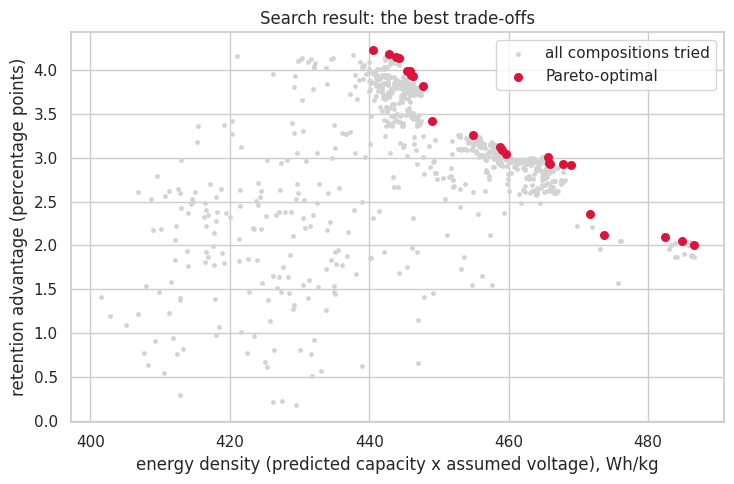

INSIGHT: highest-energy composition: Na[Mn0.53Ni0.4Ti0.04Fe0.03]O2 -> predicted capacity 153 mAh/g, retention advantage +2.0 +/- 1.3 points.
INSIGHT: moving along the red points, higher energy costs retention (more Ni) and higher retention costs energy (more Mn).


In [22]:
# ---- Collect all trials and the Pareto-optimal ones into tables ----
def trial_to_metals(trial):
    w = np.array([trial.params["w" + str(i)] for i in range(4)]) + 1e-9
    return (w / w.sum()) @ end_members

def formula_text(row):
    parts = sorted(zip(metals, row), key=lambda t: -t[1])
    text = "".join(f"{m}{v:.2f}".rstrip("0").rstrip(".") for m, v in parts if v >= 0.005)
    return "Na[" + text + "]O2"

all_metals = np.array([trial_to_metals(t) for t in study.trials])
all_energy = np.array([t.values[0] for t in study.trials])
all_adv    = np.array([t.values[1] for t in study.trials])

pareto_numbers = [t.number for t in study.best_trials]
pareto = pd.DataFrame(all_metals[pareto_numbers], columns=metals).round(2)
pareto["energy"], pareto["retention_adv"] = all_energy[pareto_numbers], all_adv[pareto_numbers]
pareto = pareto.drop_duplicates(subset=metals).reset_index(drop=True)

energy_now, adv_now, cap_now, volt_now, tab_now = evaluate(pareto[metals].values)
pareto["formula"] = [formula_text(r) for r in pareto[metals].values]
pareto["pred_capacity"] = cap_now
pareto["assumed_V"] = volt_now
pareto["uncertainty"] = retention_uncertainty(tab_now)

plt.figure(figsize=(7.5, 5))
plt.scatter(all_energy, all_adv, s=6, c="lightgrey", label="all compositions tried")
plt.scatter(pareto["energy"], pareto["retention_adv"], s=30, c="crimson", label="Pareto-optimal")
plt.xlabel("energy density (predicted capacity x assumed voltage), Wh/kg"); plt.ylabel("retention advantage (percentage points)")
plt.title("Search result: the best trade-offs"); plt.legend(); plt.tight_layout(); plt.show()

best_energy = pareto.sort_values("energy", ascending=False).iloc[0]
print(f"INSIGHT: highest-energy composition: {best_energy['formula']} -> predicted capacity {best_energy['pred_capacity']:.0f} mAh/g, "
      f"retention advantage {best_energy['retention_adv']:+.1f} +/- {best_energy['uncertainty']:.1f} points.")
print("INSIGHT: moving along the red points, higher energy costs retention (more Ni) and higher retention costs energy (more Mn).")

In [23]:
# ---- A short, readable shortlist: the 10 Pareto points with the best combined score ----
z_energy = (pareto["energy"] - pareto["energy"].mean()) / pareto["energy"].std()
z_ret    = (pareto["retention_adv"] - pareto["retention_adv"].mean()) / pareto["retention_adv"].std()
pareto["balance_score"] = z_energy + z_ret
shortlist = pareto.sort_values("balance_score", ascending=False).head(10)
columns_to_show = ["formula", "pred_capacity", "assumed_V", "energy", "retention_adv", "uncertainty"]
display(shortlist[columns_to_show].round(2).reset_index(drop=True))
print("INSIGHT: the retention advantages differ by less than their uncertainty for many candidates, so read this list as a REGION of "
      "good compositions (Mn-rich, Ni roughly 0.15-0.4, a little Ti and Fe), not as an exact ranking.")

,formula,pred_capacity,assumed_V,energy,retention_adv,uncertainty
0,Na[Mn0.53Ni0.4Ti0.04Fe0.03]O2,152.57,3.19,486.63,2.00,1.27
1,Na[Mn0.6Ni0.33Fe0.03Ti0.03]O2,151.62,3.12,468.98,2.92,1.33
2,Na[Mn0.54Ni0.4Ti0.04Fe0.03]O2,152.54,3.17,484.92,2.05,1.28
3,Na[Mn0.61Ni0.33Fe0.03Ti0.03]O2,151.04,3.10,467.85,2.93,1.33
4,Na[Mn0.73Ni0.2Fe0.04Ti0.03]O2,150.95,2.94,444.31,4.13,1.45
5,Na[Mn0.61Ni0.33Fe0.04Ti0.02]O2,150.18,3.10,465.66,3.01,1.33
6,Na[Mn0.73Ni0.19Fe0.04Ti0.03]O2,151.43,2.94,443.81,4.15,1.45
7,Na[Mn0.74Ni0.19Fe0.04Ti0.03]O2,151.09,2.93,442.79,4.18,1.46
8,Na[Mn0.55Ni0.38Ti0.04Fe0.03]O2,151.62,3.16,482.35,2.10,1.28
9,Na[Mn0.74Ni0.18Fe0.06Ti0.03]O2,153.76,2.92,445.88,3.99,1.46


INSIGHT: the retention advantages differ by less than their uncertainty for many candidates, so read this list as a REGION of good compositions (Mn-rich, Ni roughly 0.15-0.4, a little Ti and Fe), not as an exact ranking.


## 10. Reality check: the article's own material
The article synthesised **Na[Mn0.36Ni0.44Ti0.15Fe0.05]O2** and measured it. Our models never saw those numbers.
(Values below are from the article's Supporting Information, Table S5. Our voltage is only an assumption.)

In [24]:
article_material = np.array([[0.36, 0.44, 0.05, 0.15]])               # order: Mn, Ni, Fe, Ti
rows = [
    {"Window": "2.0-4.2 V", "Source": "Measured (article)",    "Capacity": 169, "Voltage": 3.23, "Energy": 546, "Retention at cycle 20": "83.0 %"},
    {"Window": "2.0-4.2 V", "Source": "Article's own model",   "Capacity": 172, "Voltage": 3.28, "Energy": 563, "Retention at cycle 20": "92.3 %"},
    {"Window": "2.0-4.1 V", "Source": "Measured (article)",    "Capacity": 146, "Voltage": 3.07, "Energy": 449, "Retention at cycle 20": "89.1 %"},
    {"Window": "2.0-4.1 V", "Source": "Article's own model",   "Capacity": 146, "Voltage": 3.13, "Energy": 457, "Retention at cycle 20": "92.5 %"}]
advantages = {}
for v_high in [4.2, 4.1]:
    energy, advantage, capacity, voltage, _ = evaluate(article_material, v_high)
    advantages[v_high] = float(advantage[0])
    rows.append({"Window": f"2.0-{v_high} V", "Source": "THIS NOTEBOOK", "Capacity": round(float(capacity[0])), "Voltage": round(float(voltage[0]), 2),
                 "Energy": round(float(energy[0])), "Retention at cycle 20": f"advantage {advantage[0]:+.1f} pts"})
display(pd.DataFrame(rows).sort_values(["Window", "Source"]).reset_index(drop=True))

print(f"INSIGHT: our capacity is {abs(169 - rows[-2]['Capacity'])} mAh/g away from the measurement at 4.2 V, well inside our typical error of {cap_rmse:.0f} mAh/g.")
direction = "higher" if advantages[4.1] > advantages[4.2] else "lower"
print(f"INSIGHT: for retention we predict {direction} stability in the narrower 4.1 V window; the experiment showed 89.1 % vs 83.0 % (higher).")

# ---- Is the article's composition a good one according to our scores? Compare with 3000 random mixtures. ----
random_mixtures = np.random.RandomState(RANDOM_SEED).dirichlet(np.ones(4), 3000) @ end_members
random_energy, random_adv, _, _, _ = evaluate(random_mixtures)
energy_a, adv_a, _, _, _ = evaluate(article_material)
print(f"INSIGHT: the article's material beats {100*(random_energy < energy_a[0]).mean():.0f}% of random mixtures on energy "
      f"and {100*(random_adv < adv_a[0]).mean():.0f}% on retention advantage.")

,Window,Source,Capacity,Voltage,Energy,Retention at cycle 20
0,2.0-4.1 V,Article's own model,146,3.13,457,92.5 %
1,2.0-4.1 V,Measured (article),146,3.07,449,89.1 %
2,2.0-4.1 V,THIS NOTEBOOK,139,3.25,451,advantage +1.4 pts
3,2.0-4.2 V,Article's own model,172,3.28,563,92.3 %
4,2.0-4.2 V,Measured (article),169,3.23,546,83.0 %
5,2.0-4.2 V,THIS NOTEBOOK,141,3.25,457,advantage +1.3 pts


INSIGHT: our capacity is 28 mAh/g away from the measurement at 4.2 V, well inside our typical error of 39 mAh/g.
INSIGHT: for retention we predict higher stability in the narrower 4.1 V window; the experiment showed 89.1 % vs 83.0 % (higher).
INSIGHT: the article's material beats 91% of random mixtures on energy and 20% on retention advantage.


## 11. Results scoreboard

In [25]:
scoreboard = pd.DataFrame([
    {"Question": "Can we predict initial capacity on unseen papers?",
     "Our result": f"R2 = {cap_r2:.2f}, typical error {cap_rmse:.0f} mAh/g (data spread {y_cap.std():.0f})",
     "Article (own lab)": "typical error 15.8 mAh/g"},
    {"Question": "Can we predict absolute retention on unseen papers?",
     "Our result": f"R2 = {best_r['Unseen paper R2']:.2f}, typical error {best_r['Unseen paper RMSE']:.0f} points",
     "Article (own lab)": "typical error 4.6 points"},
    {"Question": "Can we rank which composition retains better?",
     "Our result": f"{100*rank_acc:.0f}% of pairs correct (95% range {100*low:.0f}-{100*high:.0f}%; coin flip = 50%)",
     "Article (own lab)": "not reported"},
    {"Question": "Best composition found",
     "Our result": f"{best_energy['formula']}",
     "Article (own lab)": "Na[Mn0.36Ni0.44Ti0.15Fe0.05]O2"}])
pd.set_option("display.max_colwidth", 100)
display(scoreboard)

,Question,Our result,Article (own lab)
0,Can we predict initial capacity on unseen papers?,"R2 = 0.20, typical error 39 mAh/g (data spread 43)",typical error 15.8 mAh/g
1,Can we predict absolute retention on unseen papers?,"R2 = 0.02, typical error 20 points",typical error 4.6 points
2,Can we rank which composition retains better?,68% of pairs correct (95% range 59-76%; coin flip = 50%),not reported
3,Best composition found,Na[Mn0.53Ni0.4Ti0.04Fe0.03]O2,Na[Mn0.36Ni0.44Ti0.15Fe0.05]O2


In [26]:
# ---- Save the results so they can be opened later ----
shortlist[columns_to_show].round(3).to_csv(os.path.join(OUTPUT_DIR, "shortlist_compositions.csv"), index=False)
pareto.drop(columns=["balance_score"]).round(3).to_csv(os.path.join(OUTPUT_DIR, "all_pareto_compositions.csv"), index=False)
print("Saved: shortlist_compositions.csv and all_pareto_compositions.csv in", OUTPUT_DIR)

Saved: shortlist_compositions.csv and all_pareto_compositions.csv in /content/drive/MyDrive/resume projects/BTP/
